# London directed interaction network

The notebook summarizes the London directed interaction network.

The network is directed: `source user → target user`, where the source user mentions or replies to the target user.

The statistics were extracted via this code: 03_network_descriptives_directed.py



### Settings


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter, FuncFormatter, MaxNLocator
%matplotlib inline
BASE_DIR = "/mnt/common-hdd/group-dirs/twitter-2025-project/interaction_network_descriptives/directed"
SUMMARY_CSV = os.path.join(
    BASE_DIR,
    "interaction_network_london_summary.csv",
)
NODES_CSV = os.path.join(
    BASE_DIR,
    "interaction_network_london_nodes.csv",
)
EDGE_WEIGHT_DISTRIBUTION_CSV = os.path.join(
    BASE_DIR,
    "interaction_network_london_edge_weight_distribution.csv",
)
COMPONENT_DISTRIBUTION_CSV = os.path.join(
    BASE_DIR,
    "interaction_network_london_component_distribution.csv",
)
PLOT_DIR = os.path.join(
    BASE_DIR,
    "plots",
)
os.makedirs(PLOT_DIR, exist_ok=True)


### Read descriptive outputs


In [2]:
summary = pd.read_csv(SUMMARY_CSV)
nodes = pd.read_csv(NODES_CSV)
edge_weight_distribution = pd.read_csv(EDGE_WEIGHT_DISTRIBUTION_CSV)
component_distribution = pd.read_csv(COMPONENT_DISTRIBUTION_CSV)
print(f"Nodes loaded: {len(nodes):,}")
print(f"Edge-weight distribution rows: {len(edge_weight_distribution):,}")
print(f"Component-distribution rows: {len(component_distribution):,}")


Nodes loaded: 10,350,047
Edge-weight distribution rows: 2,070
Component-distribution rows: 9,875,879


### Helper functions




In [3]:
#The cumulative plots checks how many / what share of observations have a value of at least x?

def cumulative_distribution(series):
    values = pd.to_numeric(series, errors="coerce").dropna().to_numpy()
    values = values[values > 0]

    if len(values) == 0:
        return pd.DataFrame(columns=["x", "n_geq", "share_geq"])

    unique_values, counts = np.unique(values, return_counts=True)
    n_geq = counts[::-1].cumsum()[::-1]

    return pd.DataFrame({
        "x": unique_values,
        "n_geq": n_geq,
        "share_geq": n_geq / counts.sum(),
    })


def default_xmax(series, quantile=0.99, minimum=10):
    values = pd.to_numeric(series, errors="coerce").dropna()
    values = values[values > 0]

    if len(values) == 0:
        return minimum

    return max(minimum, int(np.ceil(values.quantile(quantile))))


def threshold_summary(series, thresholds, value_name="minimum_value"):
    values = pd.to_numeric(series, errors="coerce").dropna()
    n_total = len(values)

    rows = []
    for threshold in thresholds:
        n_geq = int((values >= threshold).sum())
        rows.append({
            value_name: threshold,
            "n_users": n_geq,
            "share_users": 100 * n_geq / n_total if n_total > 0 else np.nan,
        })

    return pd.DataFrame(rows)


def plot_cumulative_share(series, xlabel, title, filename, xmax=None):
    dist = cumulative_distribution(series)
    if dist.empty:
        return

    xmax = default_xmax(series) if xmax is None else xmax
    plot_data = dist.loc[dist["x"] <= xmax].copy()

    fig, ax = plt.subplots(figsize=(7.5, 5))
    ax.plot(plot_data["x"], plot_data["share_geq"], linewidth=1.8)
    ax.set_xlim(1, xmax)
    ax.set_ylim(0, 1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Share with value at least x")
    ax.set_title(title)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.grid(True, alpha=0.25)

    fig.tight_layout()
    fig.savefig(os.path.join(PLOT_DIR, filename), dpi=300, bbox_inches="tight")
    plt.show()


def plot_cumulative_count(series, xlabel, title, filename, xmax=None):
    dist = cumulative_distribution(series)
    if dist.empty:
        return

    xmax = default_xmax(series) if xmax is None else xmax
    plot_data = dist.loc[dist["x"] <= xmax].copy()

    fig, ax = plt.subplots(figsize=(7.5, 5))
    ax.plot(plot_data["x"], plot_data["n_geq"], linewidth=1.8)
    ax.set_xlim(1, xmax)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Number with value at least x")
    ax.set_title(title)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"{value:,.0f}"))
    ax.grid(True, alpha=0.25)

    fig.tight_layout()
    fig.savefig(os.path.join(PLOT_DIR, filename), dpi=300, bbox_inches="tight")
    plt.show()


def plot_measure_pair(series, xlabel, title_base, filename_base, xmax=None):
    plot_cumulative_share(series, xlabel, f"{title_base}: share", f"{filename_base}_share.png", xmax=xmax)
    plot_cumulative_count(series, xlabel, f"{title_base}: raw count", f"{filename_base}_count.png", xmax=xmax)


def component_size_categories(series):
    values = pd.to_numeric(series, errors="coerce")
    bins = [0, 1, 2, 5, 10, 50, 100, 1000, np.inf]
    labels = ["1", "2", "3–5", "6–10", "11–50", "51–100", "101–1,000", "1,001+"]

    return pd.cut(values, bins=bins, labels=labels, include_lowest=True)


def component_category_summary(component_df, component_type):
    subset = component_df.loc[component_df["component_type"] == component_type].copy()
    subset["size_category"] = component_size_categories(subset["n_nodes"])

    dist = (
        subset["size_category"]
        .value_counts(sort=False)
        .rename_axis("component_size")
        .reset_index(name="n_components")
    )
    dist["share_components"] = 100 * dist["n_components"] / dist["n_components"].sum()

    return dist


def plot_component_categories(dist, component_type, y_type, filename):
    fig, ax = plt.subplots(figsize=(8, 5))

    if y_type == "share":
        y = dist["share_components"] / 100
        ylabel = "Share of components"
        ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    else:
        y = dist["n_components"]
        ylabel = "Number of components"
        ax.yaxis.set_major_formatter(FuncFormatter(lambda value, pos: f"{value:,.0f}"))

    ax.bar(dist["component_size"].astype(str), y)
    ax.set_xlabel("Component size (number of users)")
    ax.set_ylabel(ylabel)
    ax.set_title(f"London interaction network: {component_type} component sizes")
    ax.grid(True, axis="y", alpha=0.25)
    plt.xticks(rotation=30, ha="right")

    fig.tight_layout()
    fig.savefig(os.path.join(PLOT_DIR, filename), dpi=300, bbox_inches="tight")
    plt.show()


In [4]:
#Create summary tables for the network measures
def descriptive_summary(series, measure_name):
    values = pd.Series(pd.to_numeric(series, errors="coerce")).dropna()

    if len(values) == 0:
        stats = {"n": 0, "sum": np.nan, "mode": np.nan, "mean": np.nan, "median": np.nan,
                 "p75": np.nan, "p90": np.nan, "p95": np.nan, "p99": np.nan, "max": np.nan}
    else:
        modes = values.mode(dropna=True)
        stats = {
            "n": len(values),
            "sum": values.sum(),
            "mode": modes.iloc[0] if len(modes) else np.nan,
            "mean": values.mean(),
            "median": values.median(),
            "p75": values.quantile(0.75),
            "p90": values.quantile(0.90),
            "p95": values.quantile(0.95),
            "p99": values.quantile(0.99),
            "max": values.max(),
        }

    return pd.DataFrame({
        "measure": measure_name,
        "statistic": list(stats.keys()),
        "value": list(stats.values()),
    })


def weighted_descriptive_summary(values, counts, measure_name):
    df = pd.DataFrame({
        "value": pd.to_numeric(values, errors="coerce"),
        "count": pd.to_numeric(counts, errors="coerce"),
    }).dropna()
    df = df.loc[df["count"] > 0].sort_values("value").copy()

    if len(df) == 0:
        stats = {"n": 0, "sum": np.nan, "mode": np.nan, "mean": np.nan, "median": np.nan,
                 "p75": np.nan, "p90": np.nan, "p95": np.nan, "p99": np.nan, "max": np.nan}
    else:
        total = df["count"].sum()
        df["cum_count"] = df["count"].cumsum()

        def weighted_quantile(q):
            return df.loc[df["cum_count"] >= q * total, "value"].iloc[0]

        stats = {
            "n": int(total),
            "sum": (df["value"] * df["count"]).sum(),
            "mode": df.loc[df["count"].idxmax(), "value"],
            "mean": np.average(df["value"], weights=df["count"]),
            "median": weighted_quantile(0.50),
            "p75": weighted_quantile(0.75),
            "p90": weighted_quantile(0.90),
            "p95": weighted_quantile(0.95),
            "p99": weighted_quantile(0.99),
            "max": df["value"].max(),
        }

    return pd.DataFrame({
        "measure": measure_name,
        "statistic": list(stats.keys()),
        "value": list(stats.values()),
    })


## 1. Overall network summary




In [5]:
summary_display = summary.copy()

if len(summary_display) == 1:
    summary_display = (
        summary_display
        .T
        .reset_index()
    )
    summary_display.columns = [
        "measure",
        "value",
    ]
summary_display


,metric,description,value
0,nodes,Number of unique users appearing as source or ...,10350047
1,directed_edges,Number of distinct non-self directed user-user...,40477389
2,total_interactions,Total number of tweet-level interactions repre...,117232348
3,network_density,Observed directed edges divided by the number ...,3.7785736229624023e-07
4,reciprocity,Share of directed edges for which the reverse ...,0.023225855798159313
...,...,...,...
87,giant_weak_component_edges,Number of directed edges contained in the larg...,40289363
88,n_strong_components,Number of strongly connected components.,9774936
89,giant_strong_component_nodes,Number of users in the largest strongly connec...,567217
90,share_nodes_in_giant_strong_component,Share of all users in the largest strongly con...,0.05480332601388187


## 2. Edge-level structure: edge weight

**Edge weight**: number of observed tweet-level interactions from one specific source user to one specific target user.


In [6]:
edge_weight_descriptives = weighted_descriptive_summary(
    edge_weight_distribution["edge_weight"],
    edge_weight_distribution["n_edges"],
    "Edge weight",
)
edge_weight_descriptives


,measure,statistic,value
0,Edge weight,n,4.047739e+07
1,Edge weight,sum,1.172323e+08
2,Edge weight,mode,1.000000e+00
3,Edge weight,mean,2.896243e+00
4,Edge weight,median,1.000000e+00
5,Edge weight,p75,2.000000e+00
6,Edge weight,p90,4.000000e+00
7,Edge weight,p95,8.000000e+00
8,Edge weight,p99,2.800000e+01
9,Edge weight,max,1.776100e+04


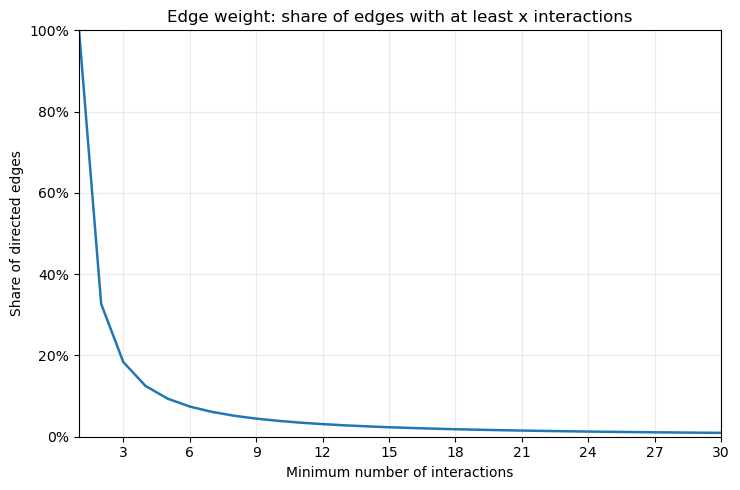

In [7]:
edge_dist = (
    edge_weight_distribution
    .loc[
        (edge_weight_distribution["edge_weight"] > 0)
        & (edge_weight_distribution["n_edges"] > 0)
    ]
    .sort_values("edge_weight")
    .copy()
)
edge_dist["n_edges_geq"] = (
    edge_dist["n_edges"]
    .iloc[::-1]
    .cumsum()
    .iloc[::-1]
)
edge_dist["share_edges_geq"] = (
    edge_dist["n_edges_geq"]
    / edge_dist["n_edges"].sum()
)
EDGE_XMAX = 30
plot_data = edge_dist.loc[
    edge_dist["edge_weight"] <= EDGE_XMAX
].copy()
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(
    plot_data["edge_weight"],
    plot_data["share_edges_geq"],
    linewidth=1.8,
)
ax.set_xlim(1, EDGE_XMAX)
ax.set_ylim(0, 1)
ax.set_xlabel("Minimum number of interactions")
ax.set_ylabel("Share of directed edges")
ax.set_title(
    "Edge weight: share of edges with at least x interactions"
)
ax.xaxis.set_major_locator(
    MaxNLocator(integer=True)
)
ax.yaxis.set_major_formatter(
    PercentFormatter(1.0)
)
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(
    os.path.join(
        PLOT_DIR,
        "edge_weight_cumulative_share.png",
    ),
    dpi=300,
    bbox_inches="tight",
)
plt.show()


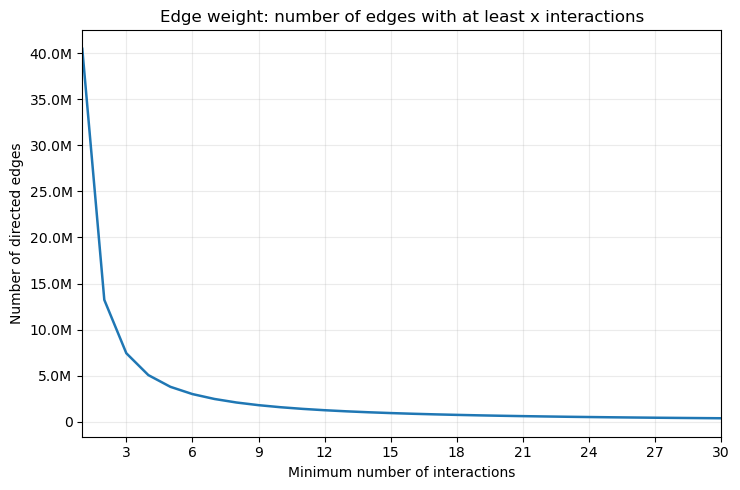

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(
    plot_data["edge_weight"],
    plot_data["n_edges_geq"],
    linewidth=1.8,
)
ax.set_xlim(1, EDGE_XMAX)
ax.set_xlabel("Minimum number of interactions")
ax.set_ylabel("Number of directed edges")
ax.set_title(
    "Edge weight: number of edges with at least x interactions"
)
ax.xaxis.set_major_locator(
    MaxNLocator(integer=True)
)
ax.yaxis.set_major_formatter(
    FuncFormatter(
        lambda value, pos:
        f"{value / 1_000_000:.1f}M"
        if value >= 1_000_000
        else f"{value:,.0f}"
    )
)
ax.grid(True, alpha=0.25)
fig.tight_layout()
fig.savefig(
    os.path.join(
        PLOT_DIR,
        "edge_weight_cumulative_count.png",
    ),
    dpi=300,
    bbox_inches="tight",
)
plt.show()


In [9]:
edge_thresholds = [
    1, 2, 3, 5, 10, 20, 30, 50, 100
]
edge_threshold_summary = []

for threshold in edge_thresholds:
    n_edges = int(
        edge_dist.loc[
            edge_dist["edge_weight"] >= threshold,
            "n_edges",
        ].sum()
    )
    edge_threshold_summary.append(
        {
            "minimum_interactions": threshold,
            "n_directed_edges": n_edges,
            "share_directed_edges": (
                100
                * n_edges
                / edge_dist["n_edges"].sum()
            ),
        }
    )
edge_threshold_summary = pd.DataFrame(
    edge_threshold_summary
)
edge_threshold_summary


,minimum_interactions,n_directed_edges,share_directed_edges
0,1,40477389,100.000000
1,2,13229131,32.682768
2,3,7437915,18.375481
3,5,3794054,9.373268
4,10,1579706,3.902687
5,20,653270,1.613913
6,30,383322,0.947003
7,50,191614,0.473385
8,100,71102,0.175659


## 3. Node-level connectivity: degree and unique neighbors

- **In-degree**: number of distinct users from whom the user receives at least one interaction.
- **Out-degree**: number of distinct users toward whom the user sends at least one interaction.
- **Total degree**: `in_degree + out_degree`. A reciprocal partner can therefore contribute once to in-degree and once to out-degree.
- **Unique neighbors**: number of distinct interaction partners in either direction. A partner is counted only once even if the relationship is reciprocal.


### In-degree



In [10]:
in_degree_descriptives = descriptive_summary(nodes["in_degree"], "In-degree",)
in_degree_descriptives


,measure,statistic,value
0,In-degree,n,1.035005e+07
1,In-degree,sum,4.047739e+07
2,In-degree,mode,1.000000e+00
3,In-degree,mean,3.910841e+00
4,In-degree,median,1.000000e+00
5,In-degree,p75,2.000000e+00
6,In-degree,p90,5.000000e+00
7,In-degree,p95,1.000000e+01
8,In-degree,p99,4.100000e+01
9,In-degree,max,4.043300e+04


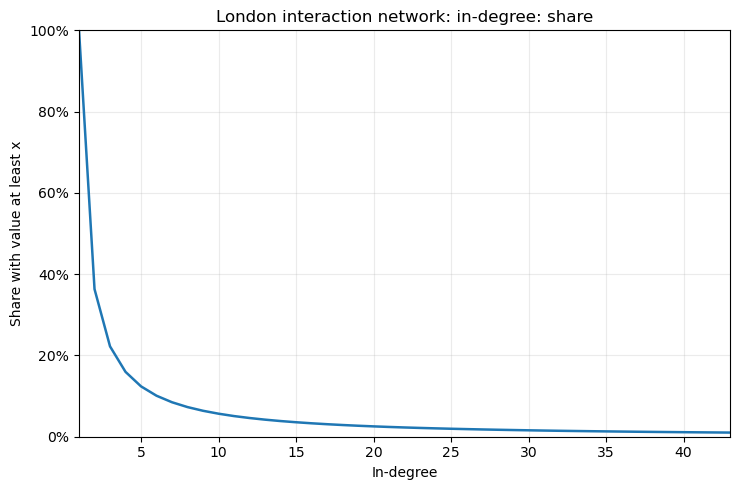

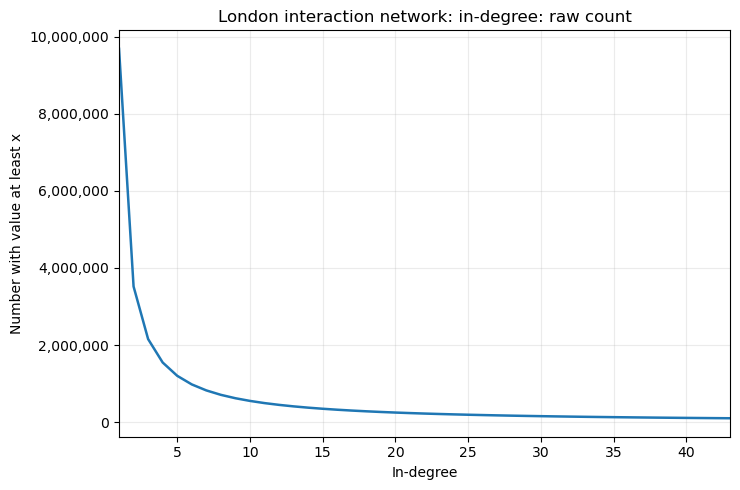

In [11]:
plot_measure_pair(nodes["in_degree"], "In-degree", "London interaction network: in-degree", "in_degree",)


In [12]:
in_degree_threshold_summary = threshold_summary(
    nodes["in_degree"],
    [1, 2, 3, 5, 10, 20, 50, 100],
    value_name="minimum_in_degree",
)
in_degree_threshold_summary


,minimum_in_degree,n_users,share_users
0,1,9689135,93.614406
1,2,3518650,33.996464
2,3,2153696,20.808563
3,5,1200560,11.599561
4,10,549047,5.304778
5,20,246674,2.383313
6,50,82226,0.794450
7,100,34797,0.336201


### Out-degree



In [13]:
out_degree_descriptives = descriptive_summary(nodes["out_degree"], "Out-degree",)
out_degree_descriptives


,measure,statistic,value
0,Out-degree,n,1.035005e+07
1,Out-degree,sum,4.047739e+07
2,Out-degree,mode,0.000000e+00
3,Out-degree,mean,3.910841e+00
4,Out-degree,median,0.000000e+00
5,Out-degree,p75,0.000000e+00
6,Out-degree,p90,2.000000e+00
7,Out-degree,p95,8.000000e+00
8,Out-degree,p99,7.100000e+01
9,Out-degree,max,2.127800e+04


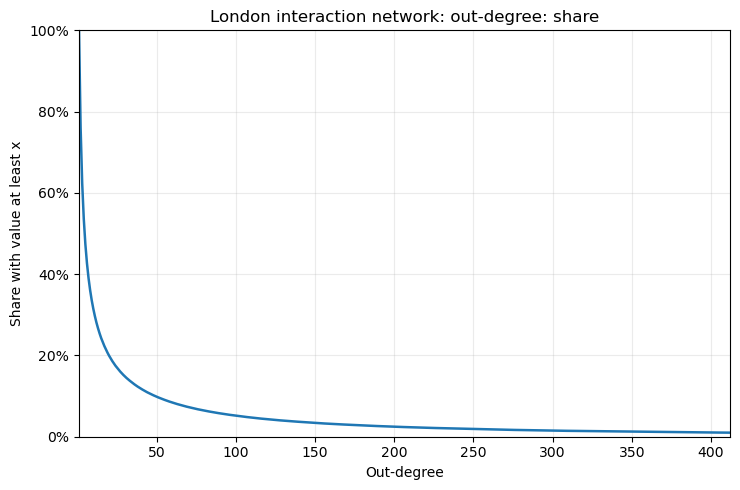

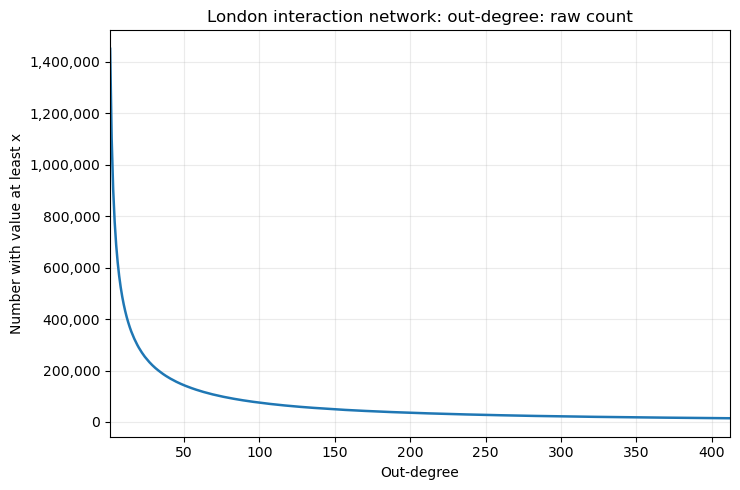

In [14]:
plot_measure_pair(nodes["out_degree"], "Out-degree", "London interaction network: out-degree", "out_degree",)


In [15]:
out_degree_threshold_summary = threshold_summary(
    nodes["out_degree"],
    [1, 2, 3, 5, 10, 20, 50, 100],
    value_name="minimum_out_degree",
)
out_degree_threshold_summary


,minimum_out_degree,n_users,share_users
0,1,1450979,14.019057
1,2,1102915,10.656135
2,3,904462,8.738724
3,5,687438,6.641883
4,10,457152,4.416907
5,20,289117,2.793388
6,50,142796,1.379665
7,100,75247,0.727021


### Total degree (in-degree + out-degree)



In [16]:
total_degree_descriptives = descriptive_summary(nodes["degree"], "Total degree",)
total_degree_descriptives


,measure,statistic,value
0,Total degree,n,1.035005e+07
1,Total degree,sum,8.095478e+07
2,Total degree,mode,1.000000e+00
3,Total degree,mean,7.821682e+00
4,Total degree,median,1.000000e+00
5,Total degree,p75,3.000000e+00
6,Total degree,p90,9.000000e+00
7,Total degree,p95,2.000000e+01
8,Total degree,p99,1.120000e+02
9,Total degree,max,4.259800e+04


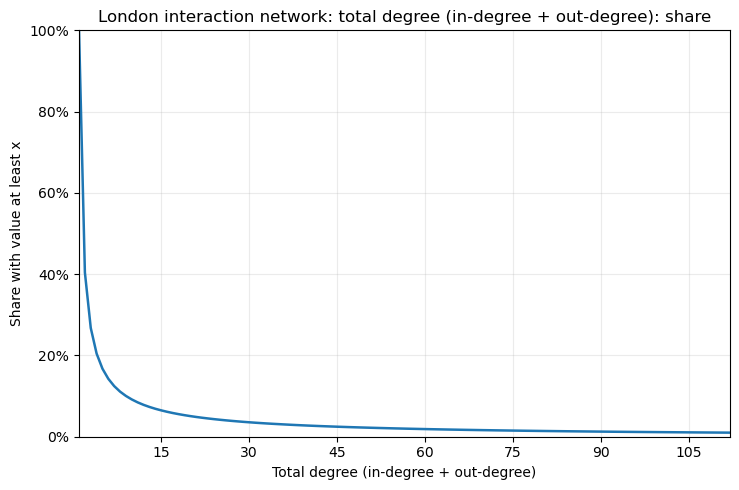

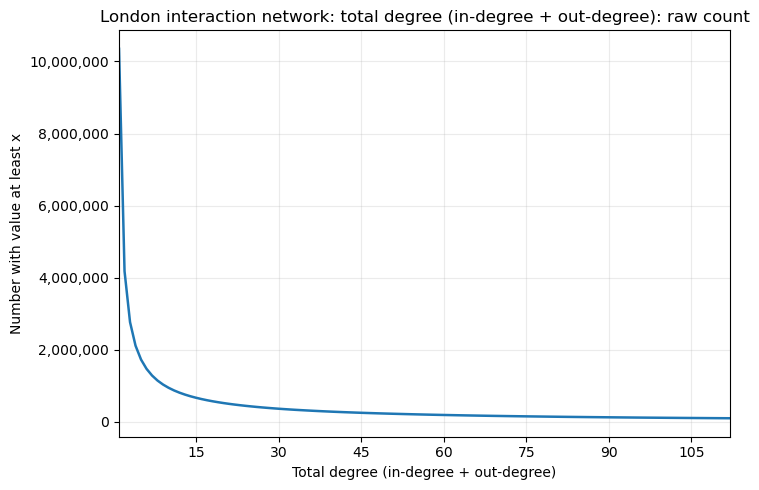

In [17]:
plot_measure_pair(nodes["degree"], "Total degree (in-degree + out-degree)", "London interaction network: total degree (in-degree + out-degree)", "total_degree",)


In [18]:
total_degree_threshold_summary = threshold_summary(
    nodes["degree"],
    [1, 2, 3, 5, 10, 20, 50, 100],
    value_name="minimum_total_degree",
)
total_degree_threshold_summary


,minimum_total_degree,n_users,share_users
0,1,10350047,100.000000
1,2,4182602,40.411430
2,3,2769715,26.760410
3,5,1730903,16.723625
4,10,949156,9.170548
5,20,524647,5.069030
6,50,231593,2.237603
7,100,116782,1.128323


### Number of unique neighbors



In [19]:
unique_neighbors_descriptives = descriptive_summary(nodes["n_unique_neighbors"], "Unique neighbors",)
unique_neighbors_descriptives


,measure,statistic,value
0,Unique neighbors,n,1.035005e+07
1,Unique neighbors,sum,8.001466e+07
2,Unique neighbors,mode,1.000000e+00
3,Unique neighbors,mean,7.730850e+00
4,Unique neighbors,median,1.000000e+00
5,Unique neighbors,p75,3.000000e+00
6,Unique neighbors,p90,8.000000e+00
7,Unique neighbors,p95,2.000000e+01
8,Unique neighbors,p99,1.100000e+02
9,Unique neighbors,max,4.199500e+04


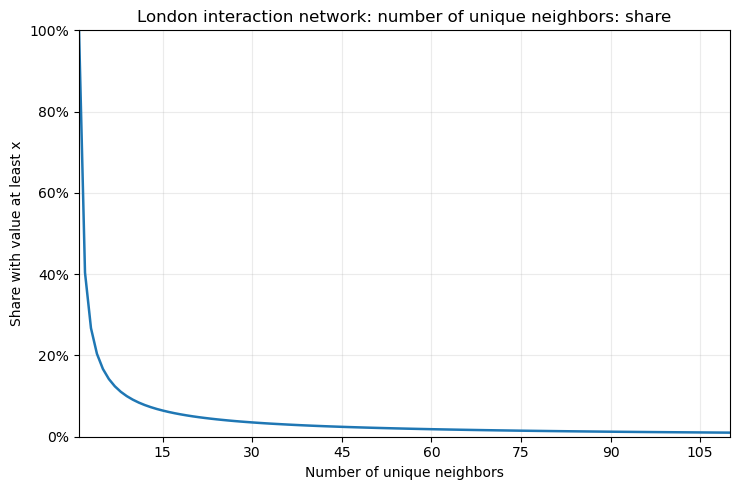

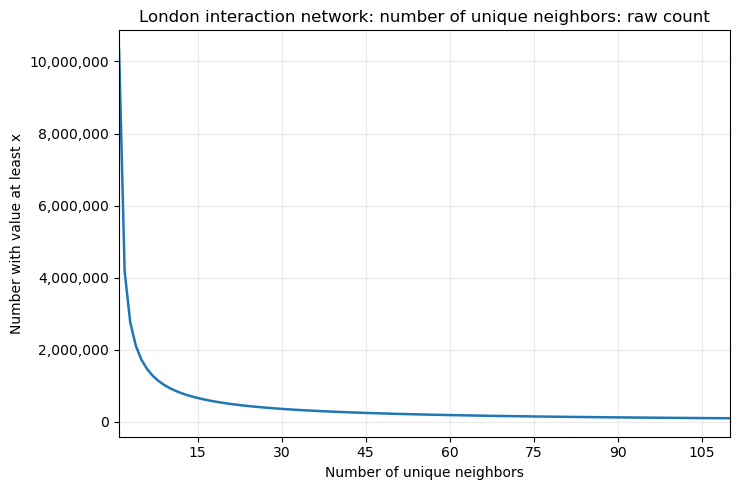

In [20]:
plot_measure_pair(nodes["n_unique_neighbors"], "Number of unique neighbors", "London interaction network: number of unique neighbors", "unique_neighbors",)


In [21]:
unique_neighbors_threshold_summary = threshold_summary(
    nodes["n_unique_neighbors"],
    [1, 2, 3, 5, 10, 20, 50, 100],
    value_name="minimum_unique_neighbors",
)
unique_neighbors_threshold_summary


,minimum_unique_neighbors,n_users,share_users
0,1,10350047,100.000000
1,2,4179734,40.383720
2,3,2765683,26.721454
3,5,1725997,16.676224
4,10,944173,9.122403
5,20,520064,5.024750
6,50,228369,2.206454
7,100,114793,1.109106


## 4. Node-level interaction intensity: strength

Strength counts **interaction events**, not distinct partners.

- **In-strength**: total number of incoming interactions received by the user.
- **Out-strength**: total number of outgoing interactions sent by the user.
- **Total strength**: `in_strength + out_strength`.



### In-strength (incoming interactions)

Total number of interaction events received by the user. Unlike degree, repeated interactions with the same partner increase strength.


In [22]:
in_strength_descriptives = descriptive_summary(nodes["in_strength"], "In-strength",)
in_strength_descriptives


,measure,statistic,value
0,In-strength,n,1.035005e+07
1,In-strength,sum,1.172323e+08
2,In-strength,mode,1.000000e+00
3,In-strength,mean,1.132675e+01
4,In-strength,median,2.000000e+00
5,In-strength,p75,4.000000e+00
6,In-strength,p90,1.400000e+01
7,In-strength,p95,3.100000e+01
8,In-strength,p99,1.520000e+02
9,In-strength,max,1.465020e+05


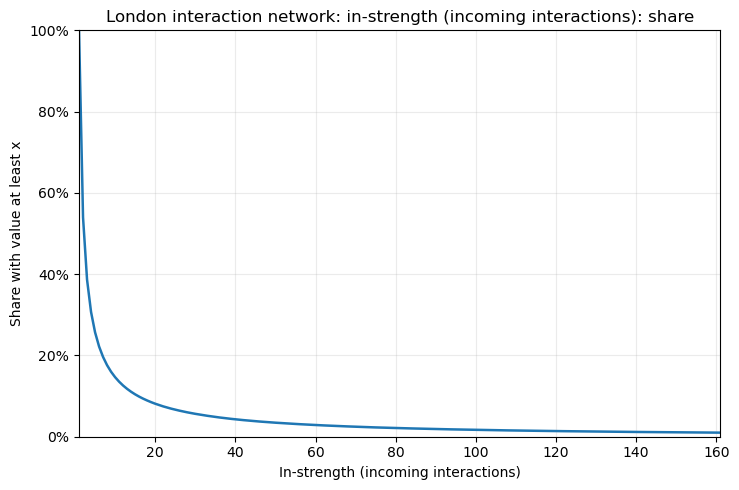

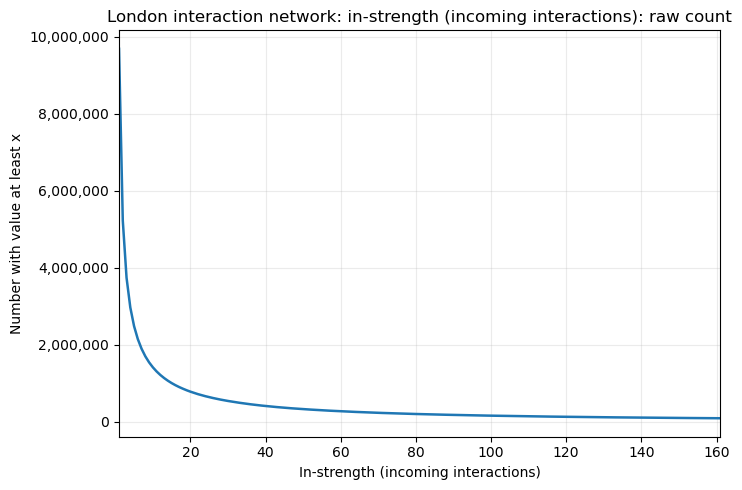

In [23]:
plot_measure_pair(nodes["in_strength"], "In-strength (incoming interactions)", "London interaction network: in-strength (incoming interactions)", "in_strength",)


In [24]:
in_strength_threshold_summary = threshold_summary(
    nodes["in_strength"],
    [1, 2, 3, 5, 10, 20, 50, 100, 500, 1000],
    value_name="minimum_incoming_interactions",
)
in_strength_threshold_summary


,minimum_incoming_interactions,n_users,share_users
0,1,9689135,93.614406
1,2,5229319,50.524592
2,3,3746060,36.193652
3,5,2489725,24.055205
4,10,1419973,13.719484
5,20,787142,7.605202
6,50,334431,3.231203
7,100,164171,1.586186
8,500,24384,0.235593
9,1000,9563,0.092396


### Out-strength (outgoing interactions)

Total number of interaction events sent by the user. Unlike degree, repeated interactions with the same partner increase strength.


In [25]:
out_strength_descriptives = descriptive_summary(nodes["out_strength"], "Out-strength",)
out_strength_descriptives


,measure,statistic,value
0,Out-strength,n,1.035005e+07
1,Out-strength,sum,1.172323e+08
2,Out-strength,mode,0.000000e+00
3,Out-strength,mean,1.132675e+01
4,Out-strength,median,0.000000e+00
5,Out-strength,p75,0.000000e+00
6,Out-strength,p90,2.000000e+00
7,Out-strength,p95,1.100000e+01
8,Out-strength,p99,1.470000e+02
9,Out-strength,max,2.947920e+05


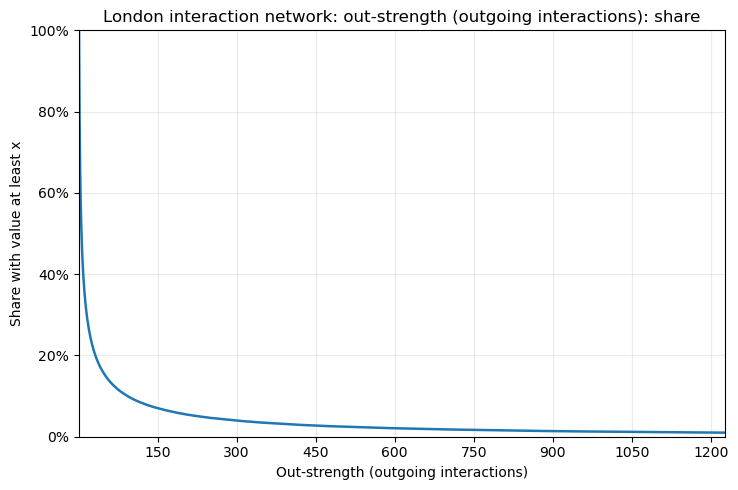

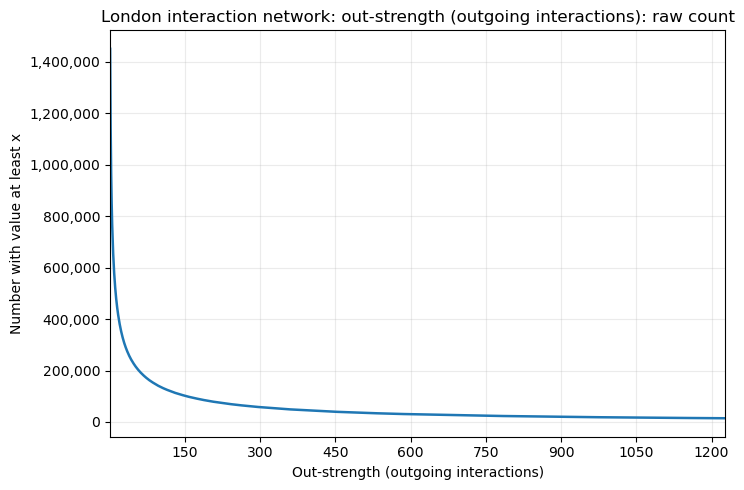

In [26]:
plot_measure_pair(nodes["out_strength"], "Out-strength (outgoing interactions)", "London interaction network: out-strength (outgoing interactions)", "out_strength",)


In [27]:
out_strength_threshold_summary = threshold_summary(
    nodes["out_strength"],
    [1, 2, 3, 5, 10, 20, 50, 100, 500, 1000],
    value_name="minimum_outgoing_interactions",
)
out_strength_threshold_summary


,minimum_outgoing_interactions,n_users,share_users
0,1,1450979,14.019057
1,2,1146536,11.077592
2,3,965604,9.329465
3,5,768132,7.421532
4,10,549342,5.307628
5,20,380416,3.675500
6,50,220564,2.131043
7,100,137701,1.330438
8,500,35924,0.347090
9,1000,18002,0.173932


### Total strength (incoming + outgoing interactions)

Total number of incoming and outgoing interaction events. 


In [28]:
total_strength_descriptives = descriptive_summary(nodes["strength"], "Total strength",)
total_strength_descriptives


,measure,statistic,value
0,Total strength,n,1.035005e+07
1,Total strength,sum,2.344647e+08
2,Total strength,mode,1.000000e+00
3,Total strength,mean,2.265349e+01
4,Total strength,median,2.000000e+00
5,Total strength,p75,6.000000e+00
6,Total strength,p90,2.100000e+01
7,Total strength,p95,5.100000e+01
8,Total strength,p99,3.110000e+02
9,Total strength,max,2.950620e+05


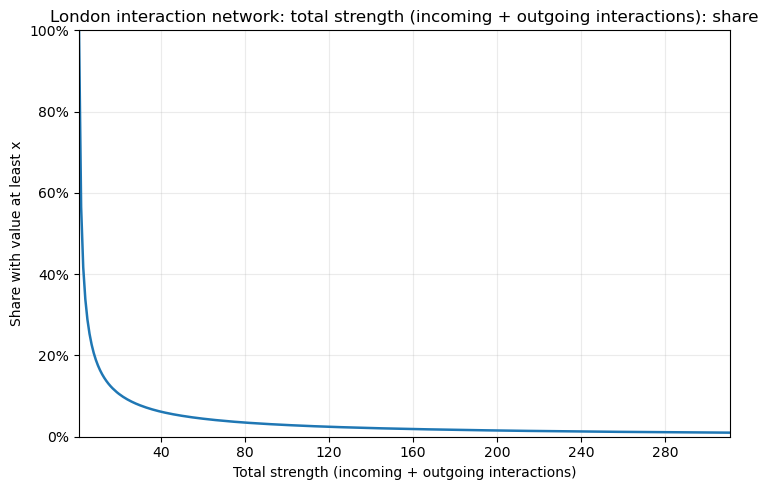

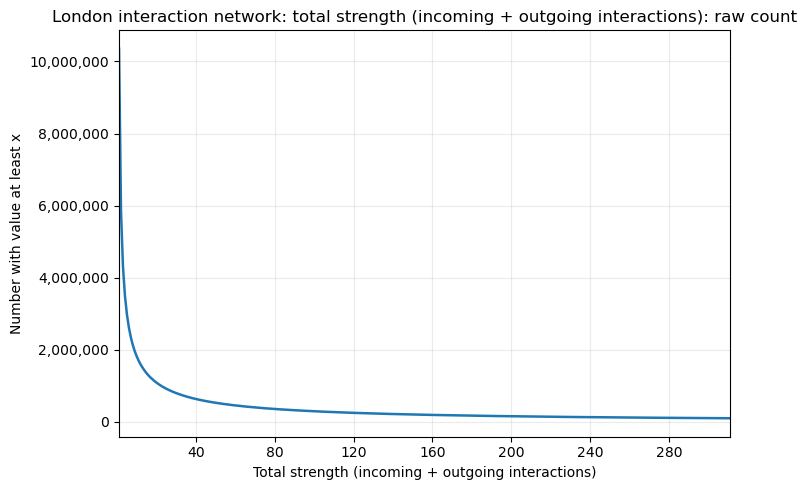

In [29]:
plot_measure_pair(nodes["strength"], "Total strength (incoming + outgoing interactions)", "London interaction network: total strength (incoming + outgoing interactions)", "strength",)


In [30]:
strength_threshold_summary = threshold_summary(
    nodes["strength"],
    [1, 2, 3, 5, 10, 20, 50, 100, 500, 1000],
    value_name="minimum_total_interactions",
)
strength_threshold_summary


,minimum_total_interactions,n_users,share_users
0,1,10350047,100.000000
1,2,5847470,56.497038
2,3,4311512,41.656932
3,5,2983953,28.830333
4,10,1816189,17.547640
5,20,1091014,10.541150
6,50,532856,5.148344
7,100,297694,2.876257
8,500,63234,0.610954
9,1000,29317,0.283255


## 5. Reciprocity

The analysis includes reciprocity at both the **network and user level**. 
**Network-level reciprocity** measures the overall extent to which directed relationships in the network are reciprocated

At the user level, `n_reciprocal_neighbors` gives the number of users with whom a user has interactions in both directions. `node_reciprocity` measures the share of a user's directed connections that are part of reciprocal relationships and is calculated as:

`2 × n_reciprocal_neighbors / degree`

where `degree = in_degree + out_degree`.


In [31]:
reciprocity_rows = summary_display.loc[
    summary_display["metric"].str.contains(
        "recipro",
        case=False,
        na=False,
    )
]

reciprocity_rows

,metric,description,value
4,reciprocity,Share of directed edges for which the reverse ...,0.023225855798159313
49,n_reciprocal_neighbors_mean,Mean number of distinct neighbors connected in...,0.09083263100157903
50,n_reciprocal_neighbors_median,Median number of distinct neighbors connected ...,0.0
51,n_reciprocal_neighbors_p75,75th percentile of number of distinct neighbor...,0.0
52,n_reciprocal_neighbors_p90,90th percentile of number of distinct neighbor...,0.0
53,n_reciprocal_neighbors_p95,95th percentile of number of distinct neighbor...,0.0
54,n_reciprocal_neighbors_p99,99th percentile of number of distinct neighbor...,2.0
55,n_reciprocal_neighbors_max,Maximum number of distinct neighbors connected...,603
56,node_reciprocity_mean,Mean share of a user's directed ties that are ...,0.00353972993403397
57,node_reciprocity_median,Median share of a user's directed ties that ar...,0.0


In [32]:
#36,643 usernél reciprok az edge-ek legalább 25%-a
reciprocity_threshold_summary = threshold_summary(
    nodes["node_reciprocity"],
    [0, 0.25, 0.50, 0.75, 1.00],
    value_name="minimum_node_reciprocity",
)

reciprocity_threshold_summary

,minimum_node_reciprocity,n_users,share_users
0,0.00,10350047,100.000000
1,0.25,36744,0.355013
2,0.50,12448,0.120270
3,0.75,3044,0.029410
4,1.00,2918,0.028193


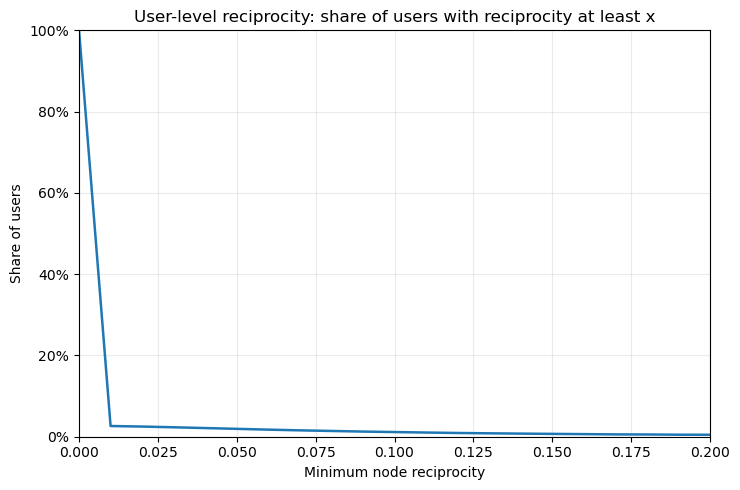

In [33]:
reciprocity_values = (
    pd.to_numeric(
        nodes["node_reciprocity"],
        errors="coerce",
    )
    .dropna()
    .to_numpy()
)

x_values = np.linspace(0, 1, 101)

share_geq = np.array([
    np.mean(reciprocity_values >= x)
    for x in x_values
])

fig, ax = plt.subplots(figsize=(7.5, 5))

ax.plot(
    x_values,
    share_geq,
    linewidth=1.8,
)

ax.set_xlim(0, 0.2)
ax.set_ylim(0, 1)

ax.set_xlabel("Minimum node reciprocity")
ax.set_ylabel("Share of users")
ax.set_title(
    "User-level reciprocity: share of users with reciprocity at least x"
)

ax.yaxis.set_major_formatter(
    PercentFormatter(1.0)
)

ax.grid(True, alpha=0.25)

fig.tight_layout()

fig.savefig(
    os.path.join(
        PLOT_DIR,
        "node_reciprocity_cumulative_share.png",
    ),
    dpi=300,
    bbox_inches="tight",
)

plt.show()


## 6. Connected components

Components describe how the network breaks into connected pieces.

- **Weakly connected components** ignore edge direction when determining whether users are connected.
- **Strongly connected components** require directed paths in both directions between every pair of users in the component.

Because component sizes are extremely skewed, sizes are grouped into interpretable categories. For each component type, the notebook shows both the **share of components** and the **raw number of components** in each size category.


### Weakly connected components


In [34]:
weak_component_size_summary = (
    component_category_summary(
        component_distribution,
        "weak",
    )
)
weak_component_size_summary


,component_size,n_components,share_components
0,1,0,0.000000
1,2,65254,64.644403
2,3–5,29847,29.568172
3,6–10,4546,4.503532
4,11–50,1279,1.267052
5,51–100,15,0.014860
6,"101–1,000",1,0.000991
7,"1,001+",1,0.000991


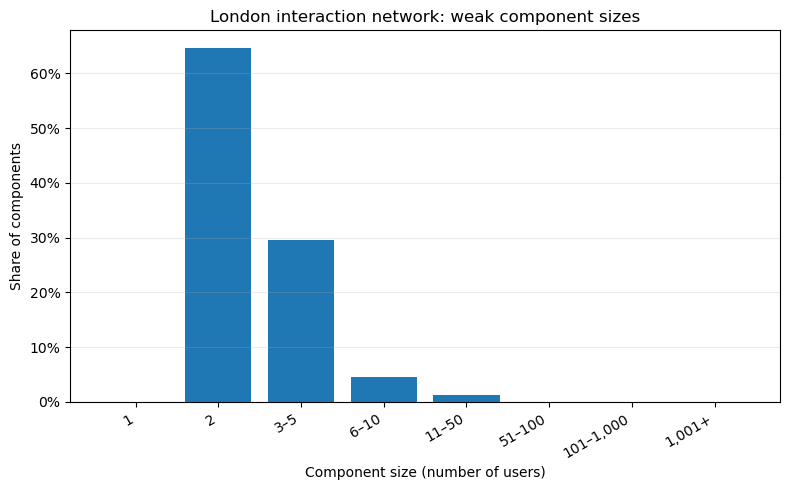

In [35]:
plot_component_categories(
    weak_component_size_summary,
    "weak",
    "share",
    "weak_component_size_categories_share.png",
)


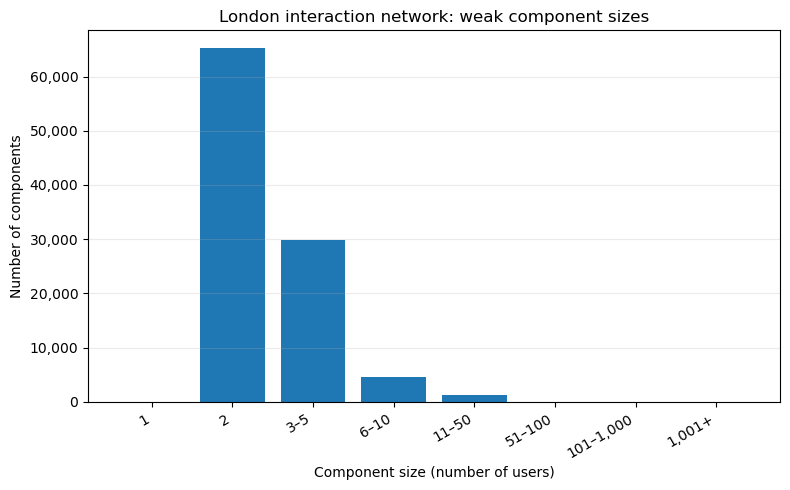

In [36]:
plot_component_categories(
    weak_component_size_summary,
    "weak",
    "count",
    "weak_component_size_categories_count.png",
)


### Strongly connected components


In [37]:
strong_component_size_summary = (
    component_category_summary(
        component_distribution,
        "strong",
    )
)
strong_component_size_summary


,component_size,n_components,share_components
0,1,9767864,99.927652
1,2,6432,0.065801
2,3–5,628,0.006425
3,6–10,10,0.000102
4,11–50,1,0.000010
5,51–100,0,0.000000
6,"101–1,000",0,0.000000
7,"1,001+",1,0.000010


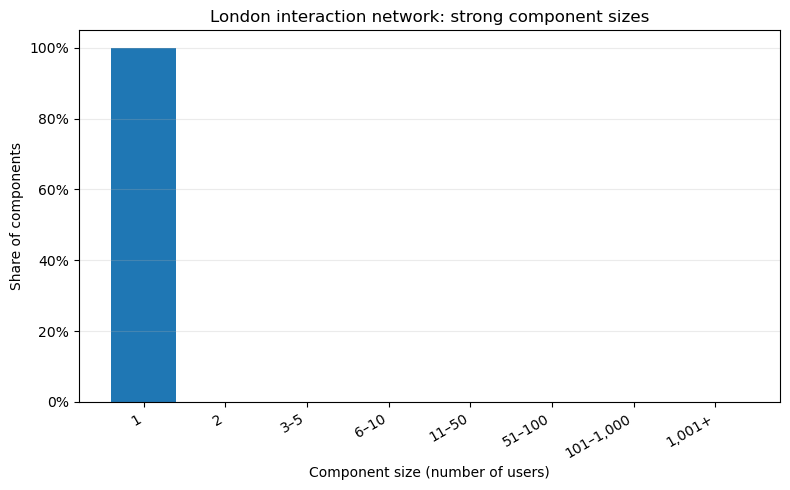

In [38]:
plot_component_categories(
    strong_component_size_summary,
    "strong",
    "share",
    "strong_component_size_categories_share.png",
)


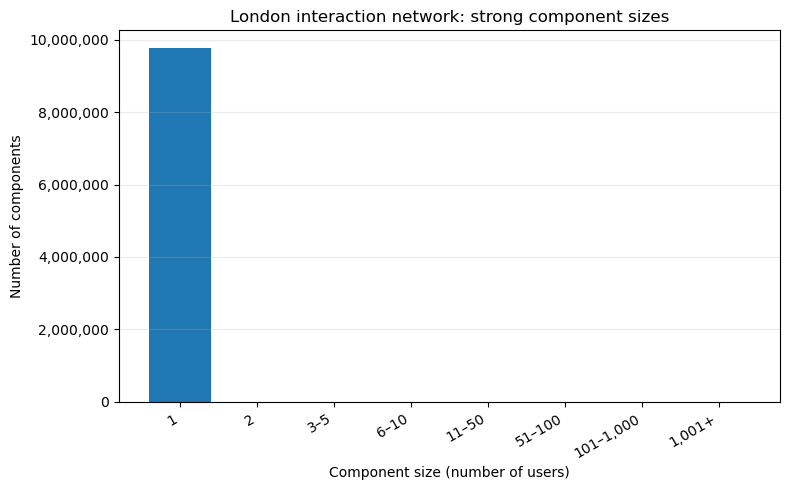

In [39]:
plot_component_categories(
    strong_component_size_summary,
    "strong",
    "count",
    "strong_component_size_categories_count.png",
)
